# Сравнение моделей SegFormer B0 и SegFormer B5

Монтируем диск

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Устанавливаем необходимые библиотеки

In [2]:
from google.colab import output
!pip install torch torchvision transformers pillow matplotlib datasets accelerate pandas tqdm gdown cityscapesscripts
output.clear()
print("Dependencies installed")

Dependencies installed


## Скачивание датасета

### Скачиваем Cityscapes

Ячейки скачивают датасет Cityscapes на диск `/content/drive/MyDrive/datasets/Cityscapes`.

Для этого нужно зарегистрироваться на сайте `https://www.cityscapes-dataset.com/` и ввести свои логин и пароль в ячейку ниже.



In [ ]:
import requests
import zipfile
from pathlib import Path
from tqdm.auto import tqdm
from getpass import getpass

save_dir = Path("/content/drive/MyDrive/datasets/Cityscapes")
save_dir.mkdir(parents=True, exist_ok=True)

# write your username and login
username = ""
password = ""

session = requests.Session()

login = session.post(
    "https://www.cityscapes-dataset.com/login/",
    data={
        "username": username,
        "password": password,
        "submit": "Login"
    },
    timeout=60
)
login.raise_for_status()

def download_cityscapes(package_id, filename):
    destination = save_dir / filename
    temp = save_dir / (filename + ".part")

    if destination.exists() and zipfile.is_zipfile(destination):
        print(f"Already downloaded: {filename}")
        return

    if temp.exists():
        raise FileExistsError(f"Temporary file already exists: {temp}")

    url = (
        "https://www.cityscapes-dataset.com/"
        f"file-handling/?packageID={package_id}"
    )

    with session.get(url, stream=True, timeout=(30, 120)) as r:
        r.raise_for_status()

        chunks = r.iter_content(chunk_size=4 * 1024 * 1024)
        first = next(chunks, b"")

        if not first.startswith(b"PK"):
            raise RuntimeError(
                "No ZIP returned"
            )

        total = int(r.headers.get("Content-Length", 0)) or None

        with open(temp, "xb") as f, tqdm(
            total=total,
            unit="B",
            unit_scale=True,
            unit_divisor=1024,
            desc=filename
        ) as bar:
            f.write(first)
            bar.update(len(first))

            for chunk in chunks:
                if chunk:
                    f.write(chunk)
                    bar.update(len(chunk))

    with zipfile.ZipFile(temp) as z:
        print(filename, "- files:", len(z.namelist()))

    temp.rename(destination)
    print("Saved:", destination)

download_cityscapes(1, "gtFine_trainvaltest.zip")
download_cityscapes(3, "leftImg8bit_trainvaltest.zip")

### Распаковываем только Cityscapes validation
По пути `/content/cityscapes`

In [ ]:
# change this path to your dataset path
save_dir = Path("/content/drive/MyDrive/datasets/Cityscapes")

In [5]:
import zipfile
from pathlib import Path

output_dir = Path("/content/cityscapes")
output_dir.mkdir(parents=True, exist_ok=True)

for filename in [
    "leftImg8bit_trainvaltest.zip",
    "gtFine_trainvaltest.zip"
]:
    with zipfile.ZipFile(save_dir / filename) as z:
        val_files = [
            name for name in z.namelist()
            if "/val/" in name and name.endswith(".png")
        ]

        print(filename, " - validation PNG:", len(val_files))
        z.extractall(output_dir, members=val_files)

print("Validation unpacked")

leftImg8bit_trainvaltest.zip  - validation PNG: 500
gtFine_trainvaltest.zip  - validation PNG: 1500
Validation unpacked


### Визуализация одного сэмпла

Скачиваем только val часть

In [6]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

Validation images: 500
Image size: (2048, 1024)
Mask size: (2048, 1024)


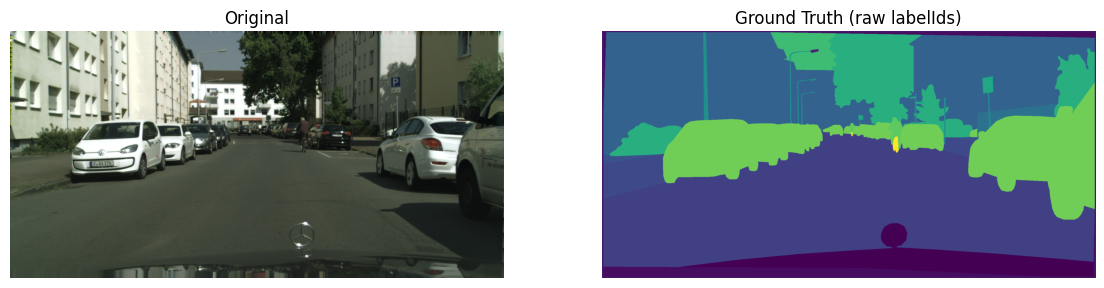

GT values: [ 1  2  3  4  7  8  9 11 13 17 20 21 23 25 26 33]


In [8]:
dataset_dir = Path("/content/cityscapes")

image_paths = sorted(
    (dataset_dir / "leftImg8bit" / "val").rglob("*_leftImg8bit.png")
)

print("Validation images:", len(image_paths))

image_path = image_paths[1]

relative_path = image_path.relative_to(
    dataset_dir / "leftImg8bit" / "val"
)

gt_path = (
    dataset_dir / "gtFine" / "val"
    / relative_path.parent
    / relative_path.name.replace(
        "_leftImg8bit.png",
        "_gtFine_labelIds.png"
    )
)

image = Image.open(image_path).convert("RGB")
gt_image = Image.open(gt_path)

print("Image size:", image.size)
print("Mask size:", gt_image.size)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(gt_image)
axes[1].set_title("Ground Truth (raw labelIds)")
axes[1].axis("off")

plt.show()

print("GT values:", np.unique(np.asarray(gt_image)))

Original GT values: [ 1  2  3  4  7  8  9 11 13 17 20 21 23 25 26 33]
TrainIds: [  0   1   2   4   5   7   8  10  12  13  18 255]


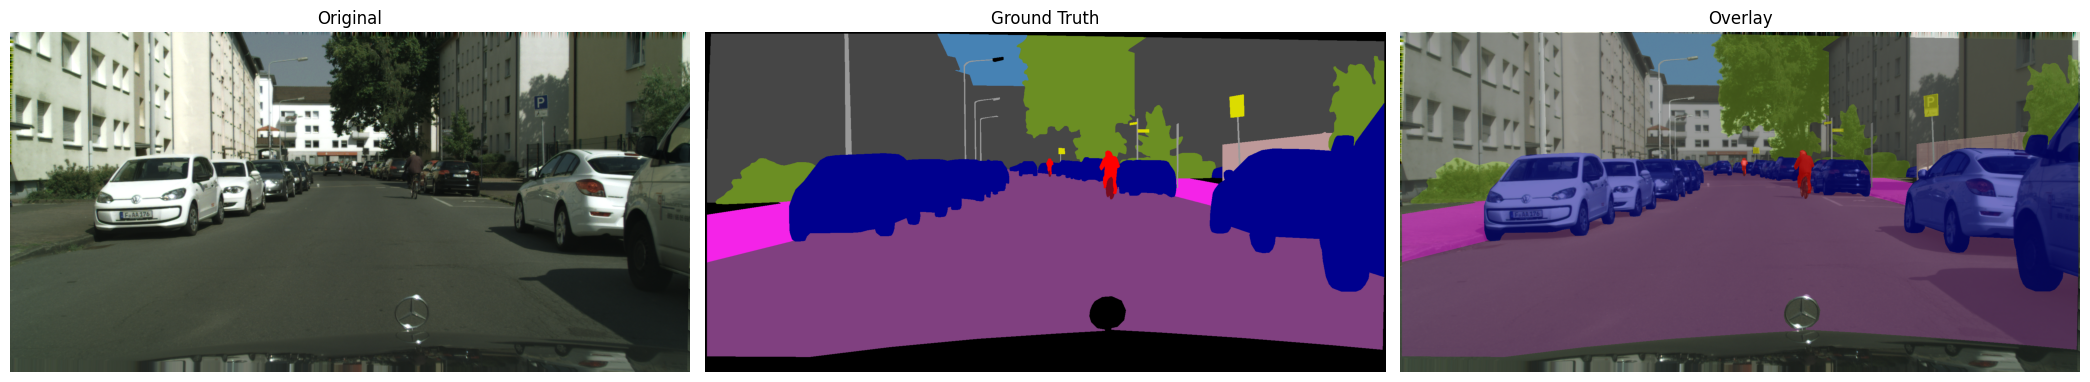

In [10]:
from cityscapesscripts.helpers.labels import labels
import numpy as np
import matplotlib.pyplot as plt

original = np.asarray(image.convert("RGB"))
gt_raw = np.asarray(gt_image)

# Mapping: labelId -> trainId
id_to_trainid = {
    label.id: label.trainId
    for label in labels
    if 0 <= label.trainId < 19
}

gt = np.full(gt_raw.shape, 255, dtype=np.uint8)

for label_id, train_id in id_to_trainid.items():
    gt[gt_raw == label_id] = train_id

print("Original GT values:", np.unique(gt_raw))
print("TrainIds:", np.unique(gt))

# Cityscapes palette
palette = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70],
    [102, 102, 156], [190, 153, 153], [153, 153, 153],
    [250, 170, 30], [220, 220, 0], [107, 142, 35],
    [152, 251, 152], [70, 130, 180], [220, 20, 60],
    [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230],
    [119, 11, 32]
], dtype=np.uint8)

valid = gt != 255

color_mask = np.zeros_like(original)
color_mask[valid] = palette[gt[valid]]

overlay = original.copy()
overlay[valid] = (
    0.45 * original[valid] + 0.55 * color_mask[valid]
).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, img, title in zip(
    axes,
    [original, color_mask, overlay],
    ["Original", "Ground Truth", "Overlay"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Подсчет статистик для B0, B5

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from PIL import Image
from tqdm.auto import tqdm
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation
from cityscapesscripts.helpers.labels import labels

DATASET_DIR = Path("/content/cityscapes")
RESULTS_DIR = Path("/content/drive/MyDrive/datasets/Cityscapes/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

N_IMAGES = 500
N_CLASSES = 19

device = "cuda" if torch.cuda.is_available() else "cpu"

model_ids = {
    "B0": "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    "B5": "nvidia/segformer-b5-finetuned-cityscapes-1024-1024",
}

class_names = [
    "road", "sidewalk", "building", "wall", "fence",
    "pole", "traffic light", "traffic sign",
    "vegetation", "terrain", "sky", "person",
    "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle"
]

# Cityscapes validation
rgb_dir = DATASET_DIR / "leftImg8bit" / "val"
gt_dir = DATASET_DIR / "gtFine" / "val"

image_paths = sorted(rgb_dir.rglob("*_leftImg8bit.png"))

print("Found validation images:", len(image_paths))

samples = []

for image_path in image_paths:
    relative_path = image_path.relative_to(rgb_dir)

    gt_path = (
        gt_dir
        / relative_path.parent
        / relative_path.name.replace(
            "_leftImg8bit.png",
            "_gtFine_labelIds.png"
        )
    )

    if not gt_path.is_file():
        raise FileNotFoundError(gt_path)

    samples.append((image_path, gt_path))

print("Ready:", len(samples))
print("Device:", device)

Found validation images: 500
Ready: 500
Device: cuda


In [15]:
# labelId -> trainId
id_to_trainid = {
    label.id: label.trainId
    for label in labels
    if 0 <= label.id < 256
    and 0 <= label.trainId < N_CLASSES
}

lookup = np.full(256, 255, dtype=np.uint8)

for label_id, train_id in id_to_trainid.items():
    lookup[label_id] = train_id


def prepare_gt(mask):
    raw = np.asarray(mask)

    if raw.ndim != 2:
        raise ValueError(f"Expected 2D mask, got {raw.shape}")

    return lookup[raw]


def update_confusion(cm, gt, pred):
    indices = (
        gt.astype(np.int64) * N_CLASSES
        + pred.astype(np.int64)
    )

    cm += np.bincount(
        indices,
        minlength=N_CLASSES ** 2
    ).reshape(N_CLASSES, N_CLASSES)


def calculate_iou(cm):
    intersection = np.diag(cm)
    union = cm.sum(0) + cm.sum(1) - intersection

    return np.divide(
        intersection,
        union,
        out=np.full(N_CLASSES, np.nan),
        where=union > 0
    )

In [16]:
processors = {}
models = {}

for name, model_id in model_ids.items():
    print(f"Loading {name}...")

    processors[name] = AutoImageProcessor.from_pretrained(
        model_id
    )

    models[name] = SegformerForSemanticSegmentation.from_pretrained(
        model_id
    ).to(device).eval()

print("All models loaded!")


def predict(name, image):
    inputs = processors[name](
        images=image,
        return_tensors="pt",
        do_resize=False
    ).to(device)

    with torch.inference_mode():
        outputs = models[name](**inputs)

        pred = processors[name].post_process_semantic_segmentation(
            outputs,
            target_sizes=[(image.height, image.width)]
        )[0]

    return pred.cpu().numpy()

Loading B0...


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading B5...


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

All models loaded!


In [17]:
N_IMAGES = 500

confusions = {
    name: np.zeros((N_CLASSES, N_CLASSES), dtype=np.int64)
    for name in models
}

total = {
    "both_correct": 0,
    "fixed": 0,
    "harmed": 0,
    "both_wrong": 0
}

class_fixed = np.zeros(N_CLASSES, dtype=np.int64)
class_harmed = np.zeros(N_CLASSES, dtype=np.int64)
class_light_errors = np.zeros(N_CLASSES, dtype=np.int64)

rows = []

for idx, (image_path, gt_path) in enumerate(
    tqdm(samples[:N_IMAGES])
):

    with Image.open(image_path) as im:
        image = im.convert("RGB")

    with Image.open(gt_path) as mask:
        gt = prepare_gt(mask)

    if gt.shape != (image.height, image.width):
        raise ValueError(f"Shape mismatch: {image_path.name}")

    # Original resolution
    light = predict("B0", image)
    heavy = predict("B5", image)

    valid = gt != 255
    n = int(valid.sum())

    if n == 0:
        continue

    lc = light == gt
    hc = heavy == gt

    both_correct = valid & lc & hc
    fixed = valid & ~lc & hc
    harmed = valid & lc & ~hc
    both_wrong = valid & ~lc & ~hc

    counts = {
        "both_correct": int(both_correct.sum()),
        "fixed": int(fixed.sum()),
        "harmed": int(harmed.sum()),
        "both_wrong": int(both_wrong.sum())
    }

    for key in total:
        total[key] += counts[key]

    update_confusion(
        confusions["B0"], gt[valid], light[valid]
    )

    update_confusion(
        confusions["B5"], gt[valid], heavy[valid]
    )

    light_errors = valid & ~lc

    class_fixed += np.bincount(
        gt[fixed], minlength=N_CLASSES
    )

    class_harmed += np.bincount(
        gt[harmed], minlength=N_CLASSES
    )

    class_light_errors += np.bincount(
        gt[light_errors], minlength=N_CLASSES
    )

    rows.append({
        "image_id": idx,
        "filename": image_path.name,
        "B0_accuracy": lc[valid].mean(),
        "B5_accuracy": hc[valid].mean(),
        "correction_rate": counts["fixed"] / n,
        "fix_recall": counts["fixed"] / max(
            int(light_errors.sum()), 1
        ),
        "harm_rate": counts["harmed"] / n,
        "net_gain": (
            counts["fixed"] - counts["harmed"]
        ) / n
    })

print(f"Processed {len(rows)} images")

  0%|          | 0/500 [00:00<?, ?it/s]

Processed 500 images



RESULTS
               Metric  Percent
    Pixel accuracy B0   95.652
    Pixel accuracy B5   96.615
              mIoU B0   74.431
              mIoU B5   81.412
      Correction rate    1.865
           Fix recall   42.888
            Harm rate    0.902
             Net gain    0.963
Oracle pixel accuracy   97.517

PER CLASS
        class  IoU_B0  IoU_B5  fixed_pixels  harmed_pixels  delta_IoU  fix_recall
         road  0.9792  0.9849       2139389         652516     0.0057      0.5059
     sidewalk  0.8353  0.8742       1660870        1160174     0.0389      0.4219
     building  0.9169  0.9334       2677371        1887943     0.0165      0.4049
         wall  0.5237  0.6360       1293625         445653     0.1122      0.4477
        fence  0.5253  0.6323       1066245         358301     0.1070      0.3557
         pole  0.6149  0.6944       1765020         499456     0.0794      0.4573
traffic light  0.6819  0.7511        178140          56196     0.0692      0.4948
 traffic sign 

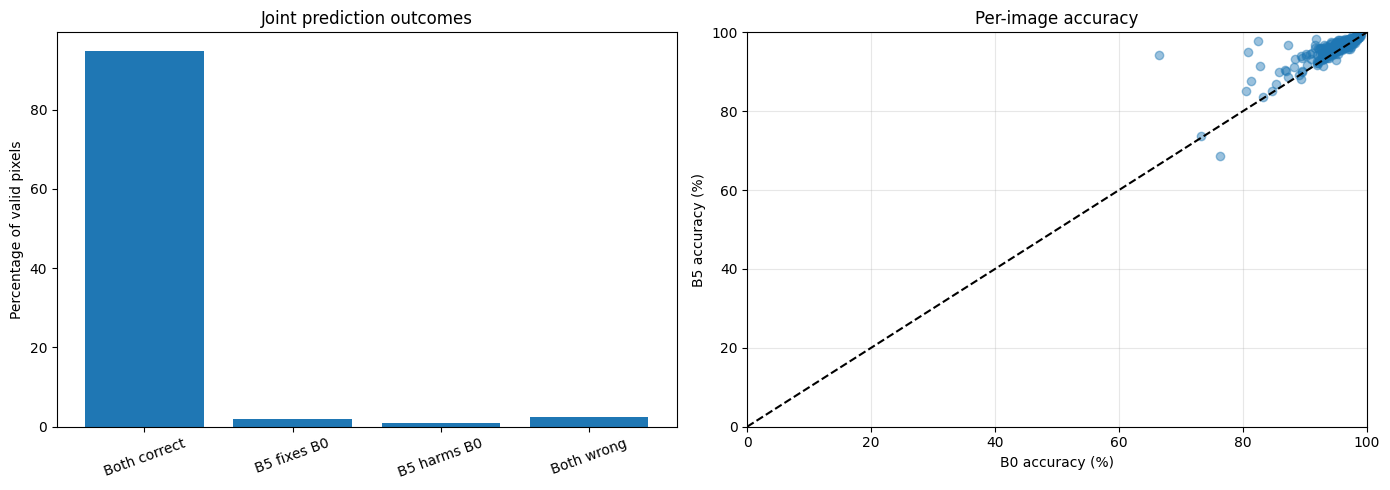

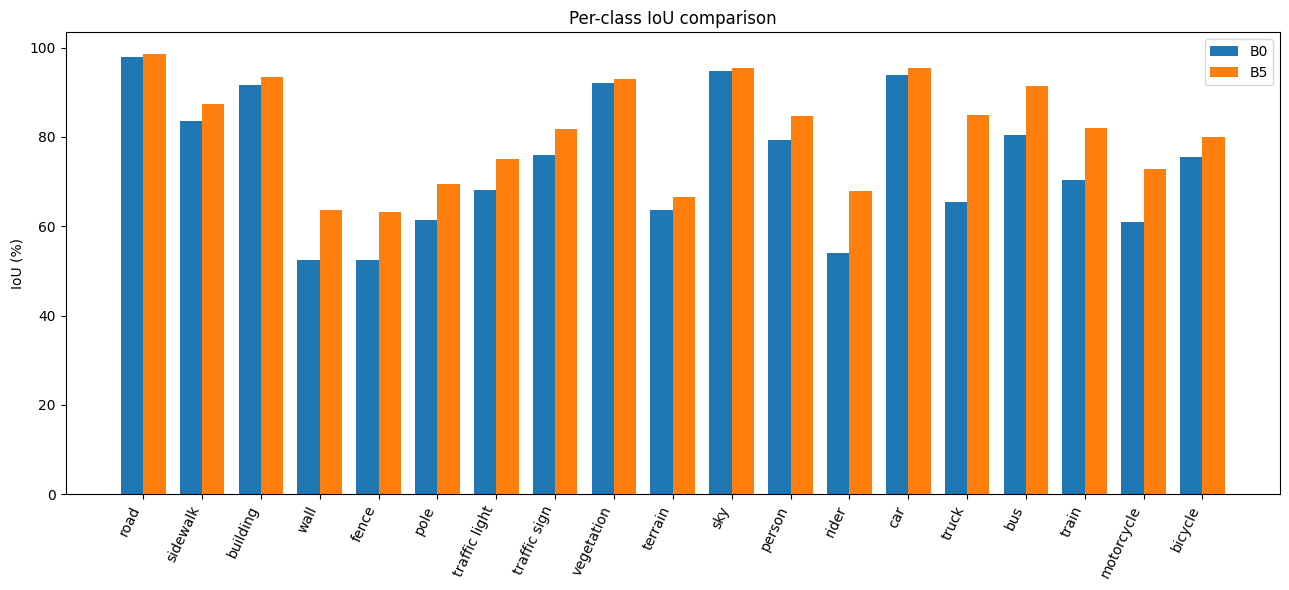


Results saved to: /content/drive/MyDrive/datasets/Cityscapes/results


In [18]:
n = sum(total.values())

if n == 0:
    raise RuntimeError("No valid pixels evaluated")

iou_b0 = calculate_iou(confusions["B0"])
iou_b5 = calculate_iou(confusions["B5"])

summary_df = pd.DataFrame({
    "Metric": [
        "Pixel accuracy B0",
        "Pixel accuracy B5",
        "mIoU B0",
        "mIoU B5",
        "Correction rate",
        "Fix recall",
        "Harm rate",
        "Net gain",
        "Oracle pixel accuracy"
    ],
    "Percent": [
        100 * (total["both_correct"] + total["harmed"]) / n,
        100 * (total["both_correct"] + total["fixed"]) / n,
        100 * np.nanmean(iou_b0),
        100 * np.nanmean(iou_b5),
        100 * total["fixed"] / n,
        100 * total["fixed"] / max(
            total["fixed"] + total["both_wrong"], 1
        ),
        100 * total["harmed"] / n,
        100 * (total["fixed"] - total["harmed"]) / n,
        100 * (1 - total["both_wrong"] / n)
    ]
})

df = pd.DataFrame(rows)

class_df = pd.DataFrame({
    "class": class_names,
    "IoU_B0": iou_b0,
    "IoU_B5": iou_b5,
    "fixed_pixels": class_fixed,
    "harmed_pixels": class_harmed
})

class_df["delta_IoU"] = (
    class_df["IoU_B5"] - class_df["IoU_B0"]
)

class_df["fix_recall"] = np.divide(
    class_fixed,
    class_light_errors,
    out=np.full(N_CLASSES, np.nan),
    where=class_light_errors > 0
)

print("\nRESULTS")
print(summary_df.round(3).to_string(index=False))

print("\nPER CLASS")
print(class_df.round(4).to_string(index=False))


# Joint prediction outcomes + per-image accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

categories = [
    "Both correct",
    "B5 fixes B0",
    "B5 harms B0",
    "Both wrong"
]

values = [total[key] / n * 100 for key in total]

axes[0].bar(categories, values)
axes[0].set_ylabel("Percentage of valid pixels")
axes[0].set_title("Joint prediction outcomes")
axes[0].tick_params(axis="x", rotation=20)

axes[1].scatter(
    df["B0_accuracy"] * 100,
    df["B5_accuracy"] * 100,
    alpha=0.45
)

axes[1].plot([0, 100], [0, 100], "k--")
axes[1].set_xlim(0, 100)
axes[1].set_ylim(0, 100)
axes[1].set_xlabel("B0 accuracy (%)")
axes[1].set_ylabel("B5 accuracy (%)")
axes[1].set_title("Per-image accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Per-class IoU
fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(N_CLASSES)
w = 0.38

ax.bar(x - w/2, iou_b0 * 100, w, label="B0")
ax.bar(x + w/2, iou_b5 * 100, w, label="B5")

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=65, ha="right")
ax.set_ylabel("IoU (%)")
ax.set_title("Per-class IoU comparison")
ax.legend()

plt.tight_layout()
plt.show()


# Save results
suffix = f"original_{len(rows)}images"

df.to_csv(
    RESULTS_DIR / f"per_image_statistics_{suffix}.csv",
    index=False
)

summary_df.to_csv(
    RESULTS_DIR / f"summary_statistics_{suffix}.csv",
    index=False
)

class_df.to_csv(
    RESULTS_DIR / f"per_class_statistics_{suffix}.csv",
    index=False
)

print("\nResults saved to:", RESULTS_DIR)

### Скорость инференса

In [19]:
import gc
import time
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

N_WARMUP = 10
N_RUNS = 30

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

with Image.open(samples[0][0]) as im:
    test_image = im.convert("RGB")

print("Image size:", test_image.size)

assert "B0" in models and "B5" in models
assert "B0" in processors and "B5" in processors

def sync_gpu():
    if device == "cuda":
        torch.cuda.synchronize()

Device: cuda
GPU: Tesla T4
Image size: (2048, 1024)


In [20]:
results = []

for name in ["B0", "B5"]:

    print(f"\n===== SegFormer-{name} =====")

    gc.collect()

    if device == "cuda":
        torch.cuda.empty_cache()

    model = models[name]
    processor = processors[name]

    params = sum(
        p.numel() for p in model.parameters()
    ) / 1e6

    inputs = processor(
        images=test_image,
        return_tensors="pt",
        do_resize=False
    ).to(device)

    print("Input shape:", inputs["pixel_values"].shape)
    print(f"Parameters: {params:.2f} M")

    # GPU warmup
    with torch.inference_mode():
        for _ in range(N_WARMUP):
            outputs = model(**inputs)

    sync_gpu()

    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

    times = []

    with torch.inference_mode():
        for _ in range(N_RUNS):

            sync_gpu()
            start = time.perf_counter()

            outputs = model(**inputs)

            sync_gpu()
            end = time.perf_counter()

            times.append((end - start) * 1000)

    times = np.array(times)

    mean_ms = times.mean()
    median_ms = np.median(times)
    p90_ms = np.percentile(times, 90)

    fps = 1000 / mean_ms

    if device == "cuda":
        peak_memory = (
            torch.cuda.max_memory_allocated() / 1024**2
        )
    else:
        peak_memory = np.nan

    print(f"Mean latency:    {mean_ms:.2f} ms")
    print(f"Median latency:  {median_ms:.2f} ms")
    print(f"P90 latency:     {p90_ms:.2f} ms")
    print(f"FPS:             {fps:.2f}")
    print(f"Peak GPU memory: {peak_memory:.1f} MB")

    results.append({
        "Model": f"SegFormer-{name}",
        "Parameters (M)": params,
        "Mean latency (ms)": mean_ms,
        "Median latency (ms)": median_ms,
        "P90 latency (ms)": p90_ms,
        "FPS": fps,
        "Peak GPU memory (MB)": peak_memory,
        "Input shape": str(tuple(inputs["pixel_values"].shape)),
    })

    del inputs, outputs

    gc.collect()

    if device == "cuda":
        torch.cuda.empty_cache()

df_benchmark = pd.DataFrame(results)

print("\n===== BENCHMARK RESULTS =====")
print(df_benchmark.round(2).to_string(index=False))

t_b0 = df_benchmark.loc[
    df_benchmark["Model"] == "SegFormer-B0",
    "Mean latency (ms)"
].iloc[0]

t_b5 = df_benchmark.loc[
    df_benchmark["Model"] == "SegFormer-B5",
    "Mean latency (ms)"
].iloc[0]

ratio = t_b5 / t_b0

print(f"\nB5 is {ratio:.2f}x slower than B0")


===== SegFormer-B0 =====
Input shape: torch.Size([1, 3, 1024, 2048])
Parameters: 3.72 M
Mean latency:    184.51 ms
Median latency:  183.82 ms
P90 latency:     187.77 ms
FPS:             5.42
Peak GPU memory: 1614.0 MB

===== SegFormer-B5 =====
Input shape: torch.Size([1, 3, 1024, 2048])
Parameters: 84.61 M
Mean latency:    1442.95 ms
Median latency:  1445.71 ms
P90 latency:     1469.10 ms
FPS:             0.69
Peak GPU memory: 3949.5 MB

===== BENCHMARK RESULTS =====
       Model  Parameters (M)  Mean latency (ms)  Median latency (ms)  P90 latency (ms)  FPS  Peak GPU memory (MB)        Input shape
SegFormer-B0            3.72             184.51               183.82            187.77 5.42               1613.98 (1, 3, 1024, 2048)
SegFormer-B5           84.61            1442.95              1445.71           1469.10 0.69               3949.53 (1, 3, 1024, 2048)

B5 is 7.82x slower than B0


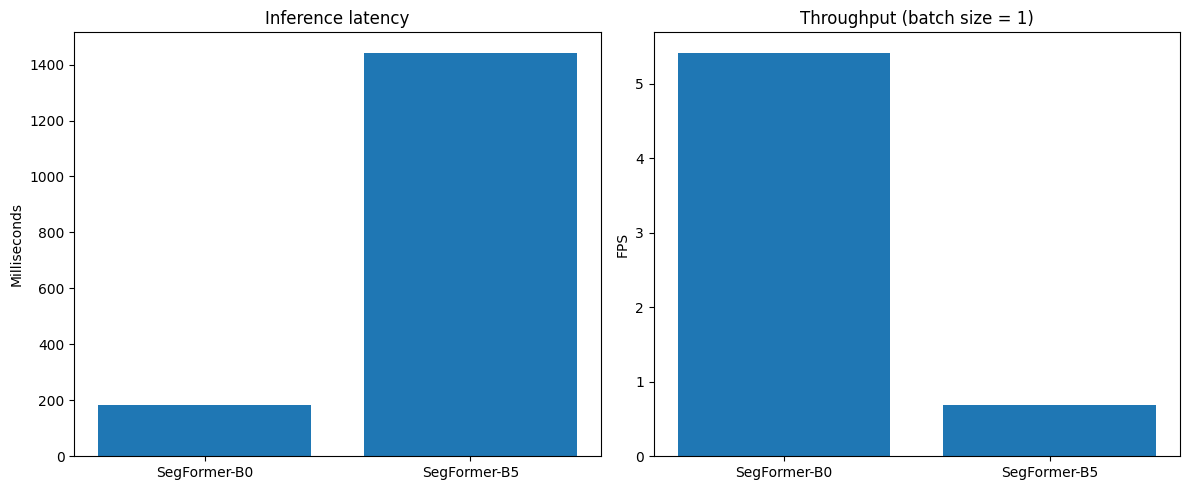

Results saved to: /content/drive/MyDrive/datasets/Cityscapes/results


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

names = df_benchmark["Model"]

axes[0].bar(
    names,
    df_benchmark["Mean latency (ms)"]
)
axes[0].set_title("Inference latency")
axes[0].set_ylabel("Milliseconds")

axes[1].bar(
    names,
    df_benchmark["FPS"]
)
axes[1].set_title("Throughput (batch size = 1)")
axes[1].set_ylabel("FPS")

plt.tight_layout()

suffix = f"{test_image.width}x{test_image.height}"

plt.savefig(
    RESULTS_DIR / f"inference_benchmark_{suffix}.png",
    dpi=180
)

plt.show()

df_benchmark.to_csv(
    RESULTS_DIR / f"inference_benchmark_{suffix}.csv",
    index=False
)

print("Results saved to:", RESULTS_DIR)

### Скачивание ACDC на диск

In [24]:
from pathlib import Path

save_dir = Path("/content/drive/MyDrive/datasets/ACDC")
save_dir.mkdir(parents=True, exist_ok=True)

#### Скачивание изображений

In [25]:
import requests
import zipfile
from pathlib import Path
from tqdm.auto import tqdm

save_dir = Path("/content/drive/MyDrive/datasets/ACDC")
save_dir.mkdir(parents=True, exist_ok=True)

archive_path = save_dir / "rgb_anon_trainvaltest.zip"
temp_path = save_dir / "rgb_anon_trainvaltest.zip.part"

package_id = "6436f2259880d97633275dfc"
base_url = "https://acdc.vision.ee.ethz.ch/api"

if temp_path.exists():
    if temp_path.stat().st_size < 100_000:
        temp_path.unlink()
    else:
        raise FileExistsError(f"Temporary folder already exists: {temp_path}")

response = requests.get(
    f"{base_url}/getPackageUri/{package_id}",
    timeout=30
)
response.raise_for_status()

token = response.json()["token"]

url = f"{base_url}/downloadPackage/{token}/rgb_anon_trainvaltest.zip"

print("Got token. Getting back to ACDC...", flush=True)

with requests.get(url, stream=True, timeout=(30, 120)) as r:
    r.raise_for_status()

    total = int(r.headers.get("Content-Length", 0)) or None

    chunks = r.iter_content(chunk_size=4 * 1024 * 1024)
    first_chunk = next(chunks)

    if not first_chunk.startswith(b"PK"):
        raise RuntimeError("No ZIP returned")

    with open(temp_path, "xb") as f, tqdm(
        total=total,
        unit="B",
        unit_scale=True,
        unit_divisor=1024,
        desc="ACDC RGB"
    ) as pbar:

        f.write(first_chunk)
        pbar.update(len(first_chunk))

        for chunk in chunks:
            if chunk:
                f.write(chunk)
                pbar.update(len(chunk))

print("Checking ZIP...", flush=True)

with zipfile.ZipFile(temp_path) as z:
    print("Files count:", len(z.namelist()))

    bad_file = z.testzip()
    if bad_file:
        raise RuntimeError(f"File corrupted: {bad_file}")

temp_path.replace(archive_path)

print(f"Size: {archive_path.stat().st_size / 1024**3:.2f} Gb")

Got token. Getting back to ACDC...


ACDC RGB: 0.00B [00:00, ?B/s]

Checking ZIP...
Files count: 8225
Size: 15.59 Gb


#### Скачивание разметки

Скачать файл `gt_trainval.zip` нужно самостоятельно с сайта https://acdc.vision.ee.ethz.ch/download .

#### Подготовка датасета ACDC

In [26]:
from google.colab import output

!unzip "/content/drive/MyDrive/datasets/ACDC/gt_trainval.zip" -d "/content"
output.clear()

In [27]:
import zipfile
from pathlib import Path

archive_path = Path(
    "/content/drive/MyDrive/datasets/ACDC/rgb_anon_trainvaltest.zip"
)

with zipfile.ZipFile(archive_path) as z:
    val_files = [
        name for name in z.namelist()
        if "/val/" in name and name.endswith("_rgb_anon.png")
    ]

    print("Validation images:", len(val_files))

    z.extractall("/content", members=val_files)

Validation images: 406


### Инференс одного сэмпла

Found images: 106
Image: (1920, 1080)
GT: (1080, 1920)
Classes: [  0   1   2   3   4   5   7   8   9  10  13 255]


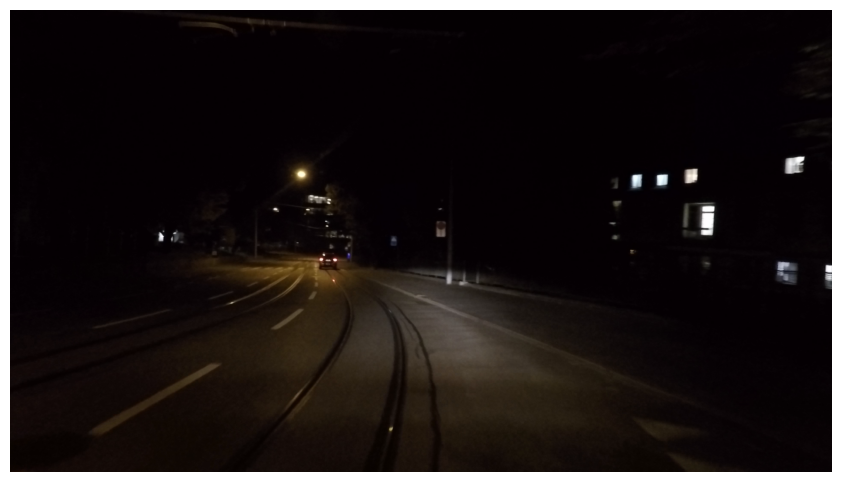

In [28]:
import zipfile
import io
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

DATA_DIR = Path("/content/drive/MyDrive/datasets/ACDC")

rgb_zip = zipfile.ZipFile(DATA_DIR / "rgb_anon_trainvaltest.zip")
gt_zip = zipfile.ZipFile(DATA_DIR / "gt_trainval.zip")

condition = "night"  # fog, night, rain, snow

images = sorted([
    f for f in rgb_zip.namelist()
    if f"/{condition}/val/" in f and f.endswith("_rgb_anon.png")
])

print("Found images:", len(images))

image_path = images[0]
gt_path = image_path.replace("rgb_anon/", "gt/").replace(
    "_rgb_anon.png", "_gt_labelTrainIds.png"
)

gt_candidates = [
    f for f in gt_zip.namelist()
    if f.endswith(gt_path.split("gt/", 1)[-1])
]

gt_path = gt_candidates[0]

image = Image.open(io.BytesIO(rgb_zip.read(image_path))).convert("RGB")
gt = np.array(Image.open(io.BytesIO(gt_zip.read(gt_path))))

print("Image:", image.size)
print("GT:", gt.shape)
print("Classes:", np.unique(gt))

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [30]:
import zipfile
import io
import numpy as np
from pathlib import Path
from PIL import Image

archive_path = Path(
    "/content/drive/MyDrive/datasets/ACDC/rgb_anon_trainvaltest.zip"
)

condition = "night"  # fog, night, rain, snow

with zipfile.ZipFile(archive_path) as z:
    images = sorted([
        name for name in z.namelist()
        if f"/{condition}/val/" in name
        and name.endswith("_rgb_anon.png")
    ])

    print("Images:", len(images))

    image_path = images[0]
    image = Image.open(io.BytesIO(z.read(image_path))).convert("RGB")

relative_path = image_path.split(f"{condition}/val/", 1)[1]

gt_path = (
    Path("/content/gt") / condition / "val"
    / relative_path.replace("_rgb_anon.png", "_gt_labelTrainIds.png")
)

gt = np.asarray(Image.open(gt_path))

print("Image shape:", image.size)
print("GT shape:", gt.shape)
print("GT classes:", np.unique(gt))

Images: 106
Image shape: (1920, 1080)
GT shape: (1080, 1920)
GT classes: [  0   1   2   3   4   5   7   8   9  10  13 255]


In [31]:
import torch
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model_ids = {
    "B0": "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    "B5": "nvidia/segformer-b5-finetuned-cityscapes-1024-1024"
}

models = {}
processors = {}

for name, model_id in model_ids.items():
    print(f"Loading {name}...")

    processors[name] = AutoImageProcessor.from_pretrained(model_id)

    models[name] = SegformerForSemanticSegmentation.from_pretrained(
        model_id
    ).to(device).eval()

def predict(name, image):
    inputs = processors[name](
        images=image,
        return_tensors="pt",
        do_resize=False
    ).to(device)

    with torch.inference_mode():
        outputs = models[name](**inputs)

        pred = processors[name].post_process_semantic_segmentation(
            outputs,
            target_sizes=[(image.height, image.width)]
        )[0]

    return pred.cpu().numpy()

print("Models loaded!")

Device: cuda
Loading B0...


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading B5...


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

Models loaded!


In [32]:
import numpy as np

palette = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70],
    [102, 102, 156], [190, 153, 153], [153, 153, 153],
    [250, 170, 30], [220, 220, 0], [107, 142, 35],
    [152, 251, 152], [70, 130, 180], [220, 20, 60],
    [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230],
    [119, 11, 32]
], dtype=np.uint8)

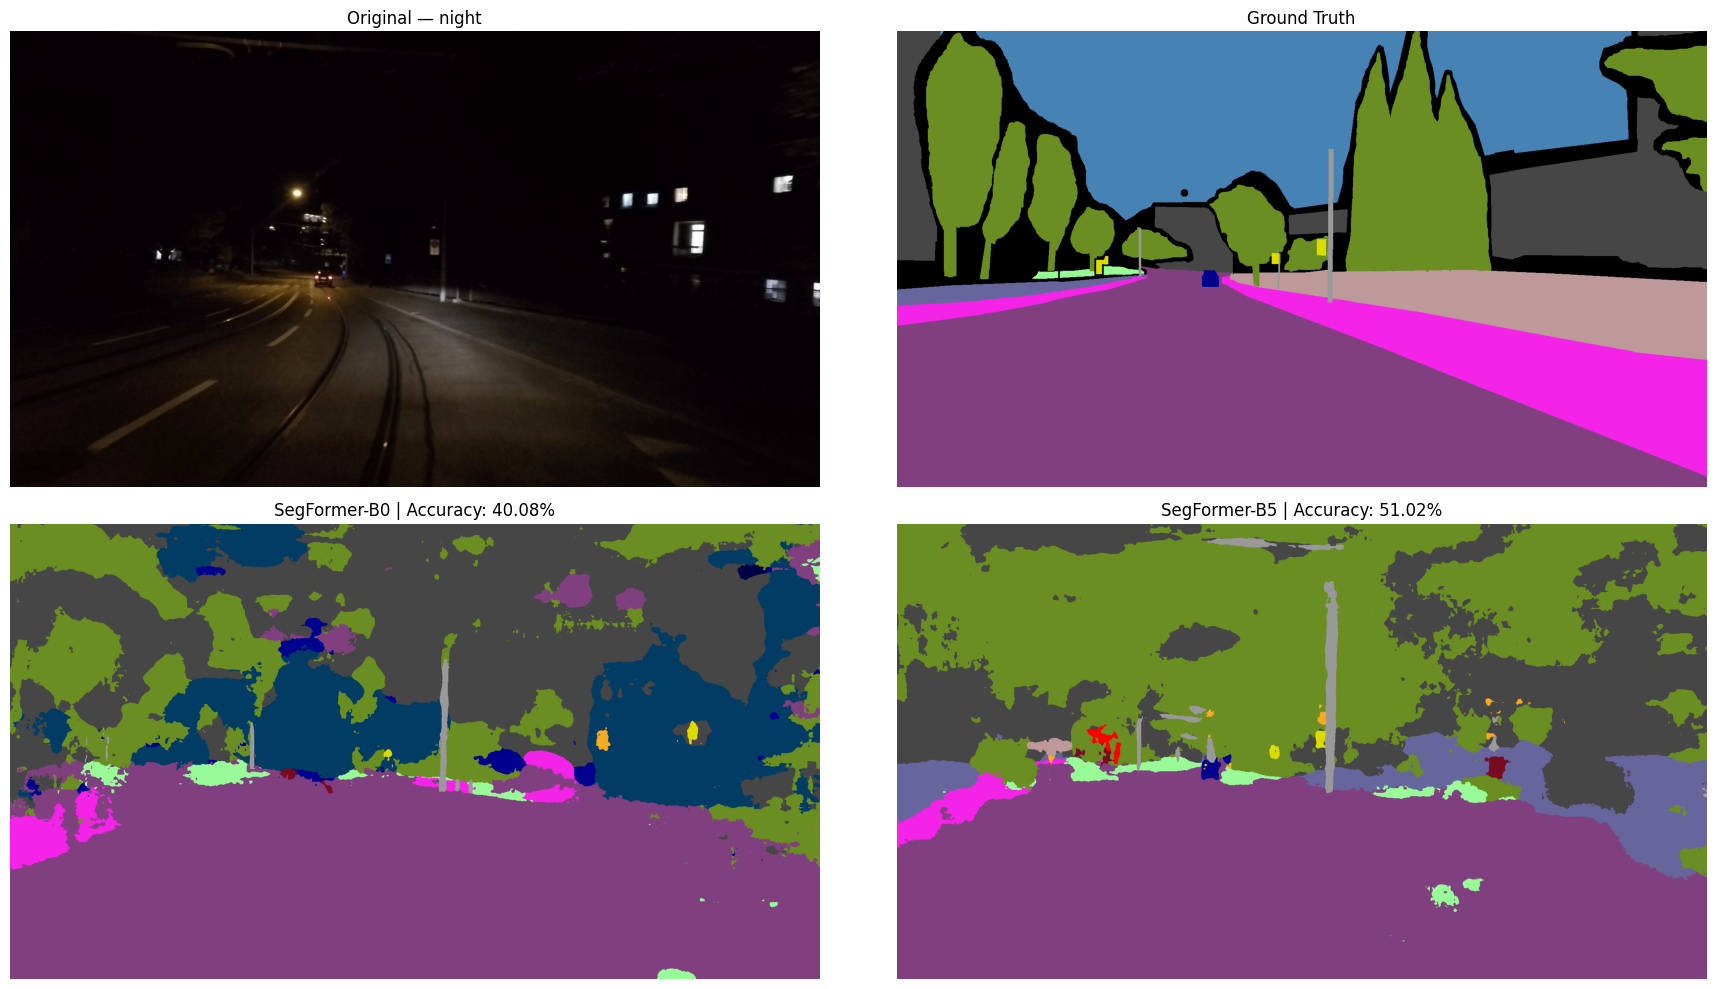

In [33]:
import matplotlib.pyplot as plt

model_image = image

pred_b0 = predict("B0", model_image)
pred_b5 = predict("B5", model_image)

pred_b0 = np.asarray(
    Image.fromarray(pred_b0.astype(np.uint8)).resize(
        image.size, Image.Resampling.NEAREST
    )
)

pred_b5 = np.asarray(
    Image.fromarray(pred_b5.astype(np.uint8)).resize(
        image.size, Image.Resampling.NEAREST
    )
)

def colorize(mask):
    result = np.zeros((*mask.shape, 3), dtype=np.uint8)
    valid = mask < 19
    result[valid] = palette[mask[valid]]
    return result

valid = gt != 255

acc_b0 = 100 * (pred_b0[valid] == gt[valid]).mean()
acc_b5 = 100 * (pred_b5[valid] == gt[valid]).mean()

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

for ax, img, title in zip(
    axes.flat,
    [
        np.asarray(image),
        colorize(gt),
        colorize(pred_b0),
        colorize(pred_b5)
    ],
    [
        "Original — night",
        "Ground Truth",
        f"SegFormer-B0 | Accuracy: {acc_b0:.2f}%",
        f"SegFormer-B5 | Accuracy: {acc_b5:.2f}%"
    ]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

FOG   | B0: 97.19% | B5: 96.98% | Gain: -0.21 p.p.
RAIN  | B0: 87.68% | B5: 90.54% | Gain: +2.86 p.p.
SNOW  | B0: 79.31% | B5: 81.53% | Gain: +2.22 p.p.


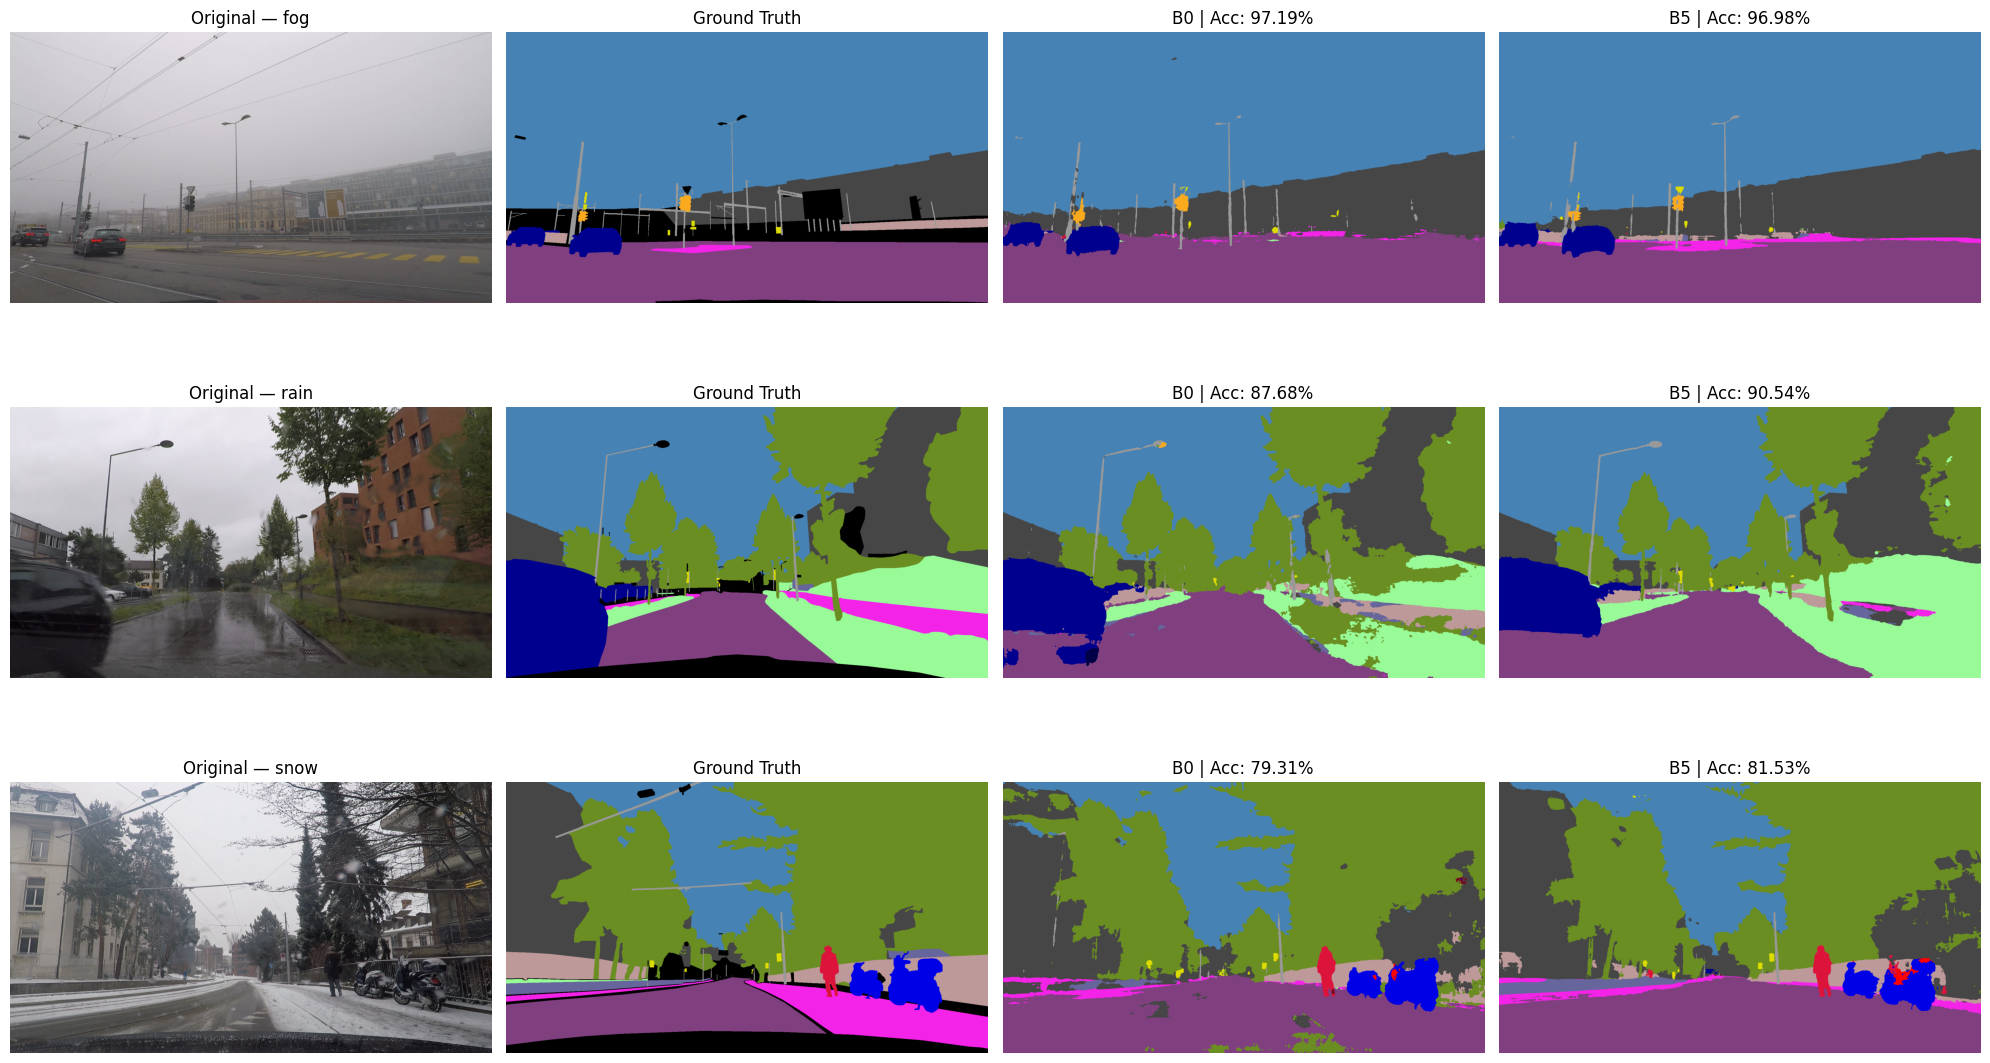

In [35]:
import zipfile
import io
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

archive_path = Path(
    "/content/drive/MyDrive/datasets/ACDC/rgb_anon_trainvaltest.zip"
)

gt_root = Path("/content/gt")
conditions = ["fog", "rain", "snow"]

fig, axes = plt.subplots(3, 4, figsize=(20, 12))

with zipfile.ZipFile(archive_path) as z:

    for row, condition in enumerate(conditions):

        images = sorted([
            name for name in z.namelist()
            if f"/{condition}/val/" in name
            and name.endswith("_rgb_anon.png")
        ])

        image_path = images[0]

        image = Image.open(
            io.BytesIO(z.read(image_path))
        ).convert("RGB")

        relative_path = image_path.split(
            f"{condition}/val/", 1
        )[1]

        gt_path = (
            gt_root / condition / "val"
            / relative_path.replace(
                "_rgb_anon.png", "_gt_labelTrainIds.png"
            )
        )

        gt = np.asarray(Image.open(gt_path))

        model_image = image

        pred_b0 = predict("B0", model_image)
        pred_b5 = predict("B5", model_image)

        pred_b0 = np.asarray(
            Image.fromarray(pred_b0.astype(np.uint8)).resize(
                image.size, Image.Resampling.NEAREST
            )
        )

        pred_b5 = np.asarray(
            Image.fromarray(pred_b5.astype(np.uint8)).resize(
                image.size, Image.Resampling.NEAREST
            )
        )

        valid = gt != 255

        acc_b0 = 100 * (pred_b0[valid] == gt[valid]).mean()
        acc_b5 = 100 * (pred_b5[valid] == gt[valid]).mean()

        def colorize(mask):
            result = np.zeros((*mask.shape, 3), dtype=np.uint8)
            valid_classes = mask < 19
            result[valid_classes] = palette[mask[valid_classes]]
            return result

        images_to_show = [
            np.asarray(image),
            colorize(gt),
            colorize(pred_b0),
            colorize(pred_b5)
        ]

        titles = [
            f"Original — {condition}",
            "Ground Truth",
            f"B0 | Acc: {acc_b0:.2f}%",
            f"B5 | Acc: {acc_b5:.2f}%"
        ]

        for col in range(4):
            axes[row, col].imshow(images_to_show[col])
            axes[row, col].set_title(titles[col])
            axes[row, col].axis("off")

        print(
            f"{condition.upper():5s} | "
            f"B0: {acc_b0:.2f}% | "
            f"B5: {acc_b5:.2f}% | "
            f"Gain: {acc_b5 - acc_b0:+.2f} p.p."
        )

plt.tight_layout()
plt.show()